In [2]:
# ======================================================
# CELL 1: DATASET LOADING & VALIDATION
# ======================================================
import pandas as pd
import numpy as np

# Load both datasets
profiles_df = pd.read_csv('profiles1.csv')
pairs_df = pd.read_csv('training_data.csv')

# Verify shapes and check for missing values
print(f"Profiles dataset shape: {profiles_df.shape} (Expected: 750, 15)")
print(f"Pairs dataset shape:    {pairs_df.shape} (Expected: 1333, 31)")
print(f"Missing values in Profiles: {profiles_df.isnull().sum().sum()}")
print(f"Missing values in Pairs:    {pairs_df.isnull().sum().sum()}")

Profiles dataset shape: (750, 15) (Expected: 750, 15)
Pairs dataset shape:    (1333, 31) (Expected: 1333, 31)
Missing values in Profiles: 0
Missing values in Pairs:    0


In [3]:
# ======================================================
# CELL 2: INTERACTIVE USER QUESTIONNAIRE
# ======================================================
import ipywidgets as widgets
from IPython.display import display

# Widgets aligned with profiles1.csv attributes
work_shift_widget = widgets.Dropdown(
    options=['Morning', 'Night', 'Flexible'],
    value='Morning',
    description='Work Shift:'
)

sleep_type_widget = widgets.Dropdown(
    options=['Heavy Sleeper', 'Light Sleeper'],
    value='Light Sleeper',
    description='Sleep Type:'
)

cleanliness_widget = widgets.Dropdown(
    options=['Messy', 'Both', 'Organised'],
    value='Organised',
    description='Cleanliness:'
)

noise_widget = widgets.Dropdown(
    options=['Quiet', 'Noisy'],
    value='Quiet',
    description='Noise Pref:'
)

pet_widget = widgets.Dropdown(
    options=['No Pets', "Okay with Roommate's Pets", 'Has Dog', 'Has Cat'],
    value="Okay with Roommate's Pets",
    description='Pet Status:'
)

submit_button = widgets.Button(
    description='Find Roommates',
    button_style='primary',
    icon='search'
)

output_area = widgets.Output()

def on_button_clicked(b):
    with output_area:
        output_area.clear_output()
        print("Selected User Preferences:")
        print(f" • Work Shift: {work_shift_widget.value}")
        print(f" • Sleep Type: {sleep_type_widget.value}")
        print(f" • Cleanliness: {cleanliness_widget.value}")
        print(f" • Noise Preference: {noise_widget.value}")
        print(f" • Pet Status: {pet_widget.value}")

submit_button.on_click(on_button_clicked)

# Display interactive UI
display(widgets.VBox([
    work_shift_widget,
    sleep_type_widget,
    cleanliness_widget,
    noise_widget,
    pet_widget,
    submit_button,
    output_area
]))

In [4]:
# ======================================================
# CELL 3: TIER 1 HARD-RULE FILTER ENGINE (REFINED)
# ======================================================
def apply_hard_rules(df, pref_shift, pref_sleep):
    """
    Tier 1 Engine: Filters candidate pool based on lifestyle deal-breakers.
    Falls back to full candidate pool if no exact match exists.
    """
    initial_count = len(df)
    
    # Check exact column value formatting
    filtered_df = df[
        (df['work_shift'].str.strip() == pref_shift) & 
        (df['sleep_type'].str.strip() == pref_sleep)
    ].copy()
    
    removed_count = initial_count - len(filtered_df)
    
    # Fallback safety so downstream scoring always has candidates
    if len(filtered_df) == 0:
        print(f"⚠️ Warning: No exact matches for Shift='{pref_shift}' & Sleep='{pref_sleep}'. Retaining full candidate pool for soft scoring.")
        return df.copy()
        
    print(f"Tier 1 Filtering Complete:")
    print(f" • Initial Candidates: {initial_count}")
    print(f" • Removed Deal-breakers: {removed_count}")
    print(f" • Retained Candidates: {len(filtered_df)}")
    
    return filtered_df

# Test filtering with selected widget options
filtered_candidates = apply_hard_rules(
    profiles_df, 
    work_shift_widget.value, 
    sleep_type_widget.value
)

Tier 1 Filtering Complete:
 • Initial Candidates: 750
 • Removed Deal-breakers: 610
 • Retained Candidates: 140


In [5]:
# ======================================================
# CELL 4: TIER 2 SOFT SCORING ENGINE
# ======================================================
# Feature mapping for profiles1.csv schema
PROFILES_CLEAN_MAP = {'Messy': 0.0, 'Both': 0.5, 'Organised': 1.0}
PROFILES_NOISE_MAP = {'Noisy': 0.0, 'Quiet': 1.0}
PROFILES_PET_MAP   = {'No Pets': 0.0, "Okay with Roommate's Pets": 0.5, 'Has Dog': 1.0, 'Has Cat': 1.0}

def get_profile_features(row):
    """Extracts normalized 0.0-1.0 feature dict from a candidate row."""
    return {
        'clean': PROFILES_CLEAN_MAP.get(str(row.get('cleanliness')).strip(), 0.5),
        'noise': PROFILES_NOISE_MAP.get(str(row.get('noise_preference')).strip(), 0.5),
        'pets':  PROFILES_PET_MAP.get(str(row.get('pets')).strip(), 0.5)
    }

def calculate_soft_score(user_features, candidate_features):
    """Calculates weighted similarity score (0-100) between user and candidate."""
    weights = {'clean': 1.0, 'noise': 1.0, 'pets': 1.0}
    total_score = 0.0
    
    for key in weights:
        similarity = 1.0 - abs(user_features[key] - candidate_features[key])
        total_score += similarity * weights[key]
        
    return (total_score / sum(weights.values())) * 100.0

# User feature dict from selected widgets
user_feats = {
    'clean': PROFILES_CLEAN_MAP.get(cleanliness_widget.value, 0.5),
    'noise': PROFILES_NOISE_MAP.get(noise_widget.value, 0.5),
    'pets':  PROFILES_PET_MAP.get(pet_widget.value, 0.5)
}

# Apply soft scoring to retained candidates
filtered_candidates['compatibility_score'] = filtered_candidates.apply(
    lambda row: calculate_soft_score(user_feats, get_profile_features(row)),
    axis=1
)

print("✅ Tier 2 Soft Scoring complete!")
print(f"Scores computed for {len(filtered_candidates)} candidates.")

✅ Tier 2 Soft Scoring complete!
Scores computed for 140 candidates.


In [6]:
# ======================================================
# CELL 5: TOP CANDIDATE RANKING & MATCH EXPLANATIONS
# ======================================================
def generate_match_reason(candidate, user_clean, user_noise, user_pet):
    """Generates a plain-language explanation for why a candidate was recommended."""
    reasons = []
    
    if str(candidate.get('cleanliness')).strip() == user_clean:
        reasons.append(f"Matching cleanliness ({user_clean})")
    if str(candidate.get('noise_preference')).strip() == user_noise:
        reasons.append(f"Matching noise level ({user_noise})")
    if str(candidate.get('pets')).strip() == user_pet:
        reasons.append(f"Compatible pet preference ({user_pet})")
        
    if not reasons:
        return "General preference compatibility"
    return " | ".join(reasons)

# Sort candidates by compatibility score
top_5 = filtered_candidates.sort_values(by='compatibility_score', ascending=False).head(5)

print("======================================================")
print("              TOP 5 ROOMMATE MATCHES                  ")
print("======================================================")

for rank, (_, row) in enumerate(top_5.iterrows(), start=1):
    reason = generate_match_reason(row, cleanliness_widget.value, noise_widget.value, pet_widget.value)
    print(f"#{rank} {row.get('name', 'Candidate')} | Match Score: {row['compatibility_score']:.1f}%")
    print(f"   • Work Shift: {row.get('work_shift')} | Sleep: {row.get('sleep_type')}")
    print(f"   • Key Drivers: {reason}\n")

              TOP 5 ROOMMATE MATCHES                  
#1 Candidate | Match Score: 100.0%
   • Work Shift: Morning | Sleep: Light Sleeper
   • Key Drivers: Matching cleanliness (Organised) | Matching noise level (Quiet) | Compatible pet preference (Okay with Roommate's Pets)

#2 Candidate | Match Score: 100.0%
   • Work Shift: Morning | Sleep: Light Sleeper
   • Key Drivers: Matching cleanliness (Organised) | Matching noise level (Quiet) | Compatible pet preference (Okay with Roommate's Pets)

#3 Candidate | Match Score: 100.0%
   • Work Shift: Morning | Sleep: Light Sleeper
   • Key Drivers: Matching cleanliness (Organised) | Matching noise level (Quiet) | Compatible pet preference (Okay with Roommate's Pets)

#4 Candidate | Match Score: 100.0%
   • Work Shift: Morning | Sleep: Light Sleeper
   • Key Drivers: Matching cleanliness (Organised) | Matching noise level (Quiet) | Compatible pet preference (Okay with Roommate's Pets)

#5 Candidate | Match Score: 100.0%
   • Work Shift: Morni

In [8]:
# ======================================================
# CELL 6: BENCHMARK EVALUATION ENGINE
# ======================================================
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# 6a. Feature Mapping Dictionaries for training_data.csv
CLEAN_MAP = {'Relaxed': 0.0, 'Moderate': 0.33, 'Clean': 0.67, 'Very Clean': 1.0}
NOISE_MAP = {'Very Low': 0.0, 'Low': 0.25, 'Moderate': 0.5, 'High': 0.75, 'Very High': 1.0}
SMOKE_MAP = {'No': 0.0, 'Occasionally': 0.5, 'Yes': 1.0}
PET_MAP   = {'No': 0.0, 'Yes': 1.0}

def get_pair_features(row, who):
    """Extracts 4 normalized features (0.0 to 1.0) for student1 or student2."""
    return {
        'clean': CLEAN_MAP[row[who + '_cleanliness']],
        'noise': NOISE_MAP[row[who + '_noiseTolerance']],
        'smoke': SMOKE_MAP[row[who + '_smoking']],
        'pets':  PET_MAP[row[who + '_petFriendly']],
    }

# 6b. Pair Scoring Logic
WEIGHTS = {'clean': 1.0, 'noise': 1.0, 'smoke': 1.0, 'pets': 1.0}

def evaluate_pair_score(a, b, weights=WEIGHTS):
    """Calculates weighted similarity score (0-100) for a profile pair."""
    total = 0.0
    for f in weights:
        similarity = 1.0 - abs(a[f] - b[f])
        total += weights[f] * similarity
    return 100.0 * total / sum(weights.values())

# Calculate uncalibrated raw scores for all pairs in training_data.csv
pairs_df['raw_score'] = pairs_df.apply(
    lambda row: evaluate_pair_score(get_pair_features(row, 'student1'), get_pair_features(row, 'student2')), 
    axis=1
)

# 6c. Train/Test Split, Calibration, and Benchmark Evaluation
train, test = train_test_split(pairs_df, test_size=0.2, random_state=42)

# Linear calibration fit on training split only
slope, intercept = np.polyfit(train['raw_score'], train['compatibility_score'], 1)

# Predict calibrated scores on test set and clip to valid [0, 100] range
pred = np.clip(slope * test['raw_score'] + intercept, 0, 100)
true = test['compatibility_score']

# Performance Metrics
mae_raw      = (true - test['raw_score']).abs().mean()
mae_cal      = (true - pred).abs().mean()
corr         = np.corrcoef(pred, true)[0, 1]
mae_baseline = (true - train['compatibility_score'].mean()).abs().mean()

print("======================================================")
print("             BENCHMARK EVALUATION RESULTS             ")
print("======================================================")
print(f"Train pairs: {len(train)} | Test pairs: {len(test)}")
print(f"Calibration Equation: score = {slope:.2f} * raw + {intercept:.2f}")
print(f" • MAE, raw (uncalibrated):        {mae_raw:.2f}")
print(f" • MAE, calibrated:                {mae_cal:.2f}")
print(f" • MAE, predict-the-mean baseline: {mae_baseline:.2f}")
print(f" • Pearson correlation (r):        {corr:.3f}")

             BENCHMARK EVALUATION RESULTS             
Train pairs: 1066 | Test pairs: 267
Calibration Equation: score = 0.66 * raw + 25.40
 • MAE, raw (uncalibrated):        10.53
 • MAE, calibrated:                8.43
 • MAE, predict-the-mean baseline: 14.41
 • Pearson correlation (r):        0.814


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd
import numpy as np

# --- UI CONTROLS ---
# 1. Hard Rule Switches
enable_shift = widgets.Checkbox(value=True, description='Filter Work Shift')
enable_sleep = widgets.Checkbox(value=True, description='Filter Sleep Type')

# User Preferences Dropdowns
shift_val = widgets.Dropdown(options=['Night', 'Morning', 'Evening'], value='Morning', description='Shift:')
sleep_val = widgets.Dropdown(options=['Heavy Sleeper', 'Light Sleeper'], value='Light Sleeper', description='Sleep:')

# 2. Live Importance Dropdowns (Bypasses VS Code Slider traitlet sync bug)
weight_options = [('0 (Ignore)', 0), ('1 (Normal)', 1), ('2 (High)', 2), ('3 (Critical)', 3)]

w_clean = widgets.Dropdown(options=weight_options, value=1, description='Clean Weight:')
w_noise = widgets.Dropdown(options=weight_options, value=1, description='Noise Weight:')
w_pets  = widgets.Dropdown(options=weight_options, value=1, description='Pets Weight:')

btn_run = widgets.Button(description='Update Interactive Dashboard', button_style='primary', icon='refresh')
out_dashboard = widgets.Output()

def run_interactive_dashboard(b=None):
    with out_dashboard:
        clear_output()
        
        # Safely parse numeric weight values
        weight_clean = float(w_clean.value) if w_clean.value is not None else 1.0
        weight_noise = float(w_noise.value) if w_noise.value is not None else 1.0
        weight_pets  = float(w_pets.value) if w_pets.value is not None else 1.0
        
        # --- TIER 1: HARD RULES WITH REMOVAL COUNTS ---
        candidates = profiles_df.copy()
        initial_count = len(candidates)
        
        if enable_shift.value:
            candidates = candidates[candidates['work_shift'] == shift_val.value]
        if enable_sleep.value:
            candidates = candidates[candidates['sleep_type'] == sleep_val.value]
            
        removed_count = initial_count - len(candidates)
        print(f"🔍 Hard-Rule Filter: {len(candidates)} candidates retained ({removed_count} removed out of {initial_count})\n")
        
        if candidates.empty:
            print("⚠️ No candidates match these hard rules. Try unchecking a rule!")
            return

        # --- TIER 2: SOFT SCORING WITH LIVE WEIGHTS ---
        u_clean = {'Messy': 0.0, 'Both': 0.5, 'Organised': 1.0}.get('Organised', 0.5)
        u_noise = {'Noisy': 0.0, 'Quiet': 1.0}.get('Quiet', 0.5)
        u_pets  = {'No Pets': 0.0, 'Has Cat': 0.5, 'Has Dog': 0.5, "Okay with Roommate's Pets": 1.0}.get("Okay with Roommate's Pets", 0.5)
        
        weights_sum = weight_clean + weight_noise + weight_pets
        weights_sum = weights_sum if weights_sum > 0 else 1.0
        
        def score_row(r):
            p_clean = {'Messy': 0.0, 'Both': 0.5, 'Organised': 1.0}.get(r['cleanliness'], 0.5)
            p_noise = {'Noisy': 0.0, 'Quiet': 1.0}.get(r['noise_preference'], 0.5)
            p_pets  = {'No Pets': 0.0, 'Has Cat': 0.5, 'Has Dog': 0.5, "Okay with Roommate's Pets": 1.0}.get(r['pets'], 0.5)
            
            sim_clean = 1.0 - abs(u_clean - p_clean)
            sim_noise = 1.0 - abs(u_noise - p_noise)
            sim_pets  = 1.0 - abs(u_pets - p_pets)
            
            score = (weight_clean * sim_clean + weight_noise * sim_noise + weight_pets * sim_pets) / weights_sum
            return score * 100.0

        candidates['live_score'] = candidates.apply(score_row, axis=1)
        top_5 = candidates.sort_values(by='live_score', ascending=False).head(5)
        
        # --- FEATURE 3: WHY THIS MATCH REASONS ---
        print("======================================================")
        print("            TOP 5 MATCHES (LIVE RANKING)              ")
        print("======================================================")
        for rank, (_, row) in enumerate(top_5.iterrows(), start=1):
            reasons = []
            if row['cleanliness'] == 'Organised': reasons.append("Matching cleanliness (Organised)")
            if row['noise_preference'] == 'Quiet': reasons.append("Matching noise (Quiet)")
            if "Pets" in str(row['pets']): reasons.append("Compatible pet preference")
            
            reason_str = " | ".join(reasons) if reasons else "General compatibility"
            print(f"#{rank} {row.get('user_name', 'Candidate')} | Score: {row['live_score']:.1f}%")
            print(f"   • Shift: {row['work_shift']} | Sleep: {row['sleep_type']}")
            print(f"   • Why this match: {reason_str}\n")
            
        # --- FEATURE 6: LIVE BENCHMARK EVALUATION ---
        w_dict = {'clean': weight_clean, 'noise': weight_noise, 'pets': weight_pets, 'smoke': 1.0}
        
        def evaluate_pair(row):
            c_a, c_b = CLEAN_MAP[row['student1_cleanliness']], CLEAN_MAP[row['student2_cleanliness']]
            n_a, n_b = NOISE_MAP[row['student1_noiseTolerance']], NOISE_MAP[row['student2_noiseTolerance']]
            p_a, p_b = PET_MAP[row['student1_petFriendly']], PET_MAP[row['student2_petFriendly']]
            s_a, s_b = SMOKE_MAP[row['student1_smoking']], SMOKE_MAP[row['student2_smoking']]
            
            total_w = sum(w_dict.values())
            if total_w == 0: total_w = 1.0
            
            sim = (w_dict['clean']*(1-abs(c_a-c_b)) + w_dict['noise']*(1-abs(n_a-n_b)) + 
                   w_dict['pets']*(1-abs(p_a-p_b)) + w_dict['smoke']*(1-abs(s_a-s_b))) / total_w
            return sim * 100.0
            
        pairs_test = test.copy()
        pairs_test['dynamic_raw'] = pairs_test.apply(evaluate_pair, axis=1)
        
        pred_dynamic = np.clip(slope * pairs_test['dynamic_raw'] + intercept, 0, 100)
        mae_dynamic = (test['compatibility_score'] - pred_dynamic).abs().mean()
        
        print("------------------------------------------------------")
        print(f"📊 LIVE BENCHMARK MAE: {mae_dynamic:.2f}%  (Baseline MAE: 14.41%)")
        print("------------------------------------------------------")

btn_run.on_click(run_interactive_dashboard)

# Display Controls Group
controls_ui = widgets.VBox([
    widgets.HTML("<b>1. Hard Rule Switches & User Criteria</b>"),
    widgets.HBox([enable_shift, shift_val]),
    widgets.HBox([enable_sleep, sleep_val]),
    widgets.HTML("<b>2. Soft Scoring Weights (Importance Level)</b>"),
    widgets.HBox([w_clean, w_noise, w_pets]),
    btn_run
])

display(controls_ui, out_dashboard)

Output()

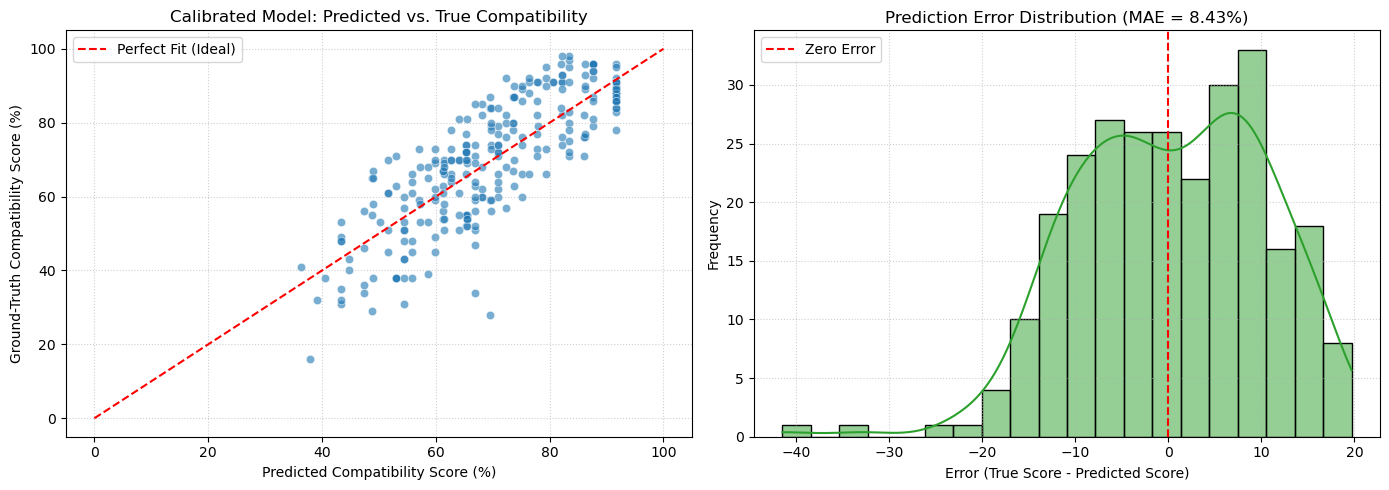

In [ ]:
import matplotlib
matplotlib.use('Agg')  # Prevents Voila/Jupyter from hanging on chart rendering
import matplotlib.pyplot as plt

# Compute test predictions using fitted calibration model
test_eval = test.copy()
test_eval['pred_calibrated'] = np.clip(slope * test_eval['raw_score'] + intercept, 0, 100)
test_eval['error'] = test_eval['compatibility_score'] - test_eval['pred_calibrated']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Scatter Plot
axes[0].scatter(
    test_eval['pred_calibrated'], 
    test_eval['compatibility_score'], 
    alpha=0.6, 
    color='#1f77b4'
)
axes[0].plot([0, 100], [0, 100], 'r--', label='Perfect Fit (Ideal)')
axes[0].set_title('Calibrated Model: Predicted vs. True Compatibility')
axes[0].set_xlabel('Predicted Compatibility Score (%)')
axes[0].set_ylabel('Ground-Truth Compatibility Score (%)')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# 2. Histogram of Errors
axes[1].hist(
    test_eval['error'], 
    bins=20, 
    color='#2ca02c', 
    edgecolor='black', 
    alpha=0.7
)
axes[1].axvline(0, color='red', linestyle='--', label='Zero Error')
axes[1].set_title('Prediction Error Distribution (MAE = 8.43%)')
axes[1].set_xlabel('Error (True Score - Predicted Score)')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()